# NVDA One-Day Value-at-Risk Project
**Lingxiao Li**

This notebook downloads daily adjusted NVDA prices directly through `quantmod`. It compares rolling standard deviation, EWMA, expanding Historical Simulation and GARCH(1,1) on exactly the same later forecast dates.

Every model predicts a threshold for the **next trading day's log return**. The confidence level is 99%, so the threshold is the lower 1% return quantile. We fit GARCH and select EWMA's lambda using earlier data, then compare all four methods on later data.

Run the cells in Google Colab to generate the tables and plots. This file contains no embedded price data, local data files or saved execution outputs. Each run retrieves the latest available history, so its date range and results may change.

## 1. Colab setup
Run the installation cell once. If it reports that NumPy, pandas or SciPy changed while already loaded, **restart the Colab runtime and continue from the imports cell**, without rerunning the installation cell. This avoids the mixed-version NumPy import error encountered earlier.

The pins retain the existing NumPy/pandas choices, add a compatible SciPy release and install GARCH's `arch` package at the start. `blobfile==3.1.0` remains compatible with quantmod's urllib3 requirement.

In [1]:
%pip install -q "numpy==2.1.3" "pandas==2.2.3" "scipy==1.15.3" "quantmod==0.1.5" "blobfile==3.1.0" "arch==8.0.0" matplotlib

import sys
from importlib.metadata import version

changed = [name for name in ("numpy", "pandas", "scipy")
           if name in sys.modules
           and getattr(sys.modules[name], "__version__", None) != version(name)]
if changed:
    raise RuntimeError(
        "Restart the Colab runtime, then continue from the imports cell. "
        "Packages changed while loaded: " + ", ".join(changed)
    )

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm
from arch import arch_model
from quantmod.markets import getTicker
from IPython.display import display, Markdown

TICKER = "NVDA"
START_DATE = "2020-01-01"

ALPHA = 0.01
TRAIN_FRACTION = 0.80
ROLLING_WINDOW = 21
WARMUP = 252
HIST_MIN = 252
LAMBDA_GRID = [0.50, 0.60, 0.70, 0.72, 0.80, 0.85, 0.90, 0.94, 0.97, 0.99, 0.995]

## 2. Download prices and calculate returns
Retrieve daily prices directly using `getTicker(...).history(auto_adjust=True)`. Omitting an end date requests history through the latest available trading data.

Remove duplicate dates only, report missing values, and stop if closing prices cannot support log-return calculations. No extreme-return observations are removed. The index records the exchange-local trading date.

In [3]:
prices = getTicker(TICKER).history(
    start=START_DATE,
    interval="1d",
    auto_adjust=True,
    keepna=True
)

if prices.empty:
    raise ValueError("No prices were retrieved.")

prices.index = pd.DatetimeIndex([date.date() for date in prices.index])
prices.index.name = "Date"

duplicates = prices.index.duplicated(keep="last")
print("Duplicate dates removed:", int(duplicates.sum()))
prices = prices.loc[~duplicates].sort_index().copy()

print("\nMissing values by column:")
print(prices.isna().sum())
if not np.isfinite(prices["Close"].to_numpy(dtype=float)).all() or (prices["Close"] <= 0).any():
    raise ValueError("Investigate missing, infinite or nonpositive closes before proceeding.")

df = prices.copy()
# At date t, Return is the daily return that has just finished: log(S_t / S_{t-1})
df["Return"] = np.log(df["Close"] / df["Close"].shift(1))
# Put tomorrow's realised return on today's forecast row: log(S_{t+1} / S_t)
df["Return_1D_Forward"] = df["Return"].shift(-1)

print(f"\nPrice range: {df.index[0].date()} to {df.index[-1].date()}")
print("Price observations:", len(df))
display(df[["Close", "Return", "Return_1D_Forward"]].tail())

Duplicate dates removed: 0

Missing values by column:
Open            0
High            0
Low             0
Close           0
Volume          0
Dividends       0
Stock Splits    0
dtype: int64

Price range: 2020-01-02 to 2026-11-13
Price observations: 1727


,Close,Return,Return_1D_Forward
Date,,,
2026-11-09,178.669998,-0.043641,-0.056293
2026-11-10,168.889999,-0.056293,0.028255
2026-11-11,173.729996,0.028255,-0.044371
2026-11-12,166.190002,-0.044371,-0.020302
2026-11-13,162.850006,-0.020302,NaN


## 3. Use earlier data to fit, and later data to test
At the close of date $t$, today's daily return $r_t=\ln(S_t/S_{t-1})$ is known. Tomorrow's return $r_{t+1}=\ln(S_{t+1}/S_t)$ is still unknown. The forecast stored on row $t$ is always checked against tomorrow's return, stored in `Return_1D_Forward` on that same row.

We use the first 80% of daily returns to fit the GARCH parameters and choose EWMA's lambda. When choosing lambda, we only score forecasts whose next-day outcomes are already known by the end of training.

Suppose day C ends training. The forecast made on day C−1 can be scored using the observed return on day C. At the close of day C, we make the first test forecast for day C+1. **No observed trading day is removed between training and testing.**

During testing, the GARCH parameters and the chosen EWMA lambda stay fixed. Their variance forecasts still update using each newly observed daily return. HistSim also adds new observed daily returns to its history. All four methods are scored on the same dates.

The final row has no next-day outcome yet, so its forecast cannot be scored. The first daily return is also undefined because no earlier price is available.

In [4]:
r_pct = 100 * df["Return"].iloc[1:]
if not np.isfinite(r_pct.to_numpy()).all():
    raise ValueError("Unexpected missing daily returns; do not bridge missing trading-day prices silently.")

n_train = int(TRAIN_FRACTION * len(r_pct))
if n_train < 1 or n_train >= len(r_pct):
    raise ValueError("The split must leave both training and test returns.")

last_training_date = r_pct.index[n_train - 1]
test_origin_pos = df.index.get_loc(last_training_date)
first_pos = df.index.get_loc(df["Return"].first_valid_index())
seed_pos = first_pos + WARMUP - 1
positions = np.arange(len(df))

if seed_pos + 1 > test_origin_pos or test_origin_pos + 1 >= len(df):
    raise ValueError("Not enough history for the warm-up, tuning and later backtest.")
if first_pos + HIST_MIN - 1 > test_origin_pos:
    raise ValueError("HistSim needs more daily return history before the common test period.")

# A tuning forecast at t is allowed only if its outcome at t+1 is within training.
tuning_mask = (
    (positions >= seed_pos)
    & (positions + 1 <= test_origin_pos)
    & df["Return_1D_Forward"].notna().to_numpy()
)

print("Fit GARCH and select lambda using history through:", last_training_date.date())
print("First test forecast is made after the close of:", last_training_date.date())
print("Its next-day outcome is observed on:", r_pct.index[n_train].date())
print("EWMA tuning comparisons:", int(tuning_mask.sum()))

Fit GARCH and select lambda using history through: 2025-07-01
First test forecast is made after the close of: 2025-07-01
Its next-day outcome is observed on: 2025-07-02
EWMA tuning comparisons: 1128


### A picture of training, forecasting and scoring
The dashed line **C** marks the close of the final training day. The first row shows the full dataset. The next rows zoom in around C; each step is one trading day.

- **Past return:** the return from C−1 to C is known at the close of C.
- **Forward return:** the return from C to C+1 is what the first test forecast predicts.
- **Last tuning score:** a forecast made on C−1 can be scored using the outcome ending on C.
- **First test score:** the forecast made on C is scored only after C+1 closes. It is not used to choose lambda.

GARCH may use all observed daily returns through C when fitting its parameters. EWMA may use them to update variance. Neither may use the still-unknown return ending on C+1 during training.

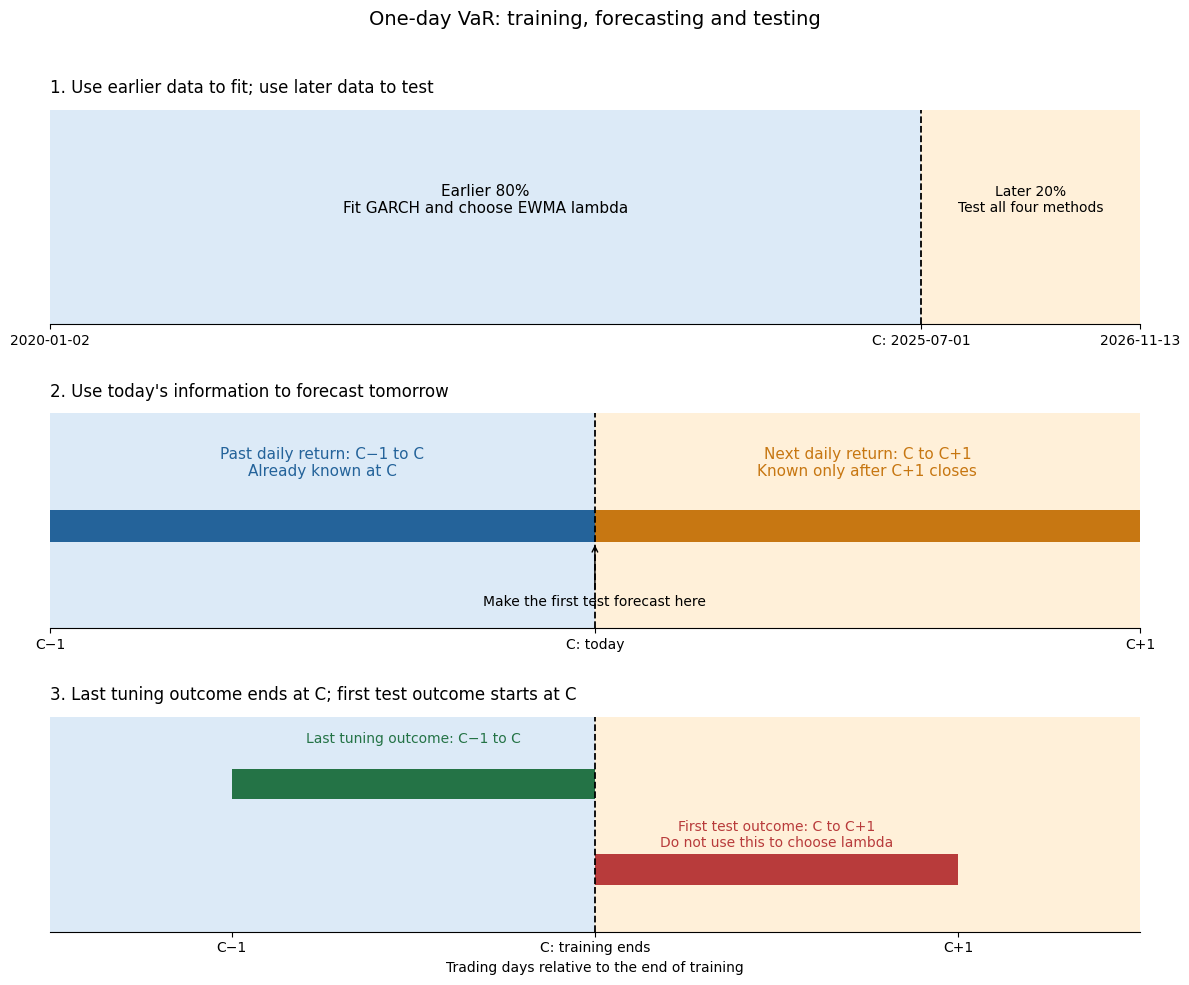

In [5]:
# Timeline only: this draws the split; it does not fit another model
c = test_origin_pos
last = len(df) - 1
train_color, test_color = "#dceaf7", "#fff0d9"
blue, orange, green, red = "#24639a", "#c77712", "#247346", "#b83b3b"

fig, axes = plt.subplots(3, 1, figsize=(12, 10))

# A. Full history: earlier data for fitting, later data for testing
ax = axes[0]
ax.axvspan(0, c, color=train_color)
ax.axvspan(c, last, color=test_color)
ax.axvline(c, color="black", linestyle="--", linewidth=1.3)
ax.text(c / 2, 0.58, "Earlier 80%\nFit GARCH and choose EWMA lambda",
        ha="center", va="center", fontsize=11)
ax.text((c + last) / 2, 0.58, "Later 20%\nTest all four methods",
        ha="center", va="center", fontsize=10)
ax.set_xlim(0, last)
ax.set_ylim(0, 1)
ax.set_xticks([0, c, last])
ax.set_xticklabels([str(df.index[0].date()), "C: " + str(last_training_date.date()),
                    str(df.index[-1].date())])
ax.set_title("1. Use earlier data to fit; use later data to test", loc="left", pad=12)

# B. Today's known return and tomorrow's unknown return
ax = axes[1]
ax.axvspan(-1, 0, color=train_color)
ax.axvspan(0, 1, color=test_color)
ax.axvline(0, color="black", linestyle="--", linewidth=1.3)
ax.broken_barh([(-1, 1)], (0.40, 0.15), facecolors=blue)
ax.broken_barh([(0, 1)], (0.40, 0.15), facecolors=orange)
ax.text(-0.5, 0.77, "Past daily return: C−1 to C\nAlready known at C",
        ha="center", va="center", color=blue, fontsize=11)
ax.text(0.5, 0.77, "Next daily return: C to C+1\nKnown only after C+1 closes",
        ha="center", va="center", color=orange, fontsize=11)
ax.annotate("Make the first test forecast here", xy=(0, 0.4), xytext=(0, 0.12),
            ha="center", va="center", arrowprops={"arrowstyle": "->"}, fontsize=10)
ax.set_xlim(-1, 1)
ax.set_ylim(0, 1)
ax.set_xticks([-1, 0, 1])
ax.set_xticklabels(["C−1", "C: today", "C+1"])
ax.set_title("2. Use today's information to forecast tomorrow", loc="left", pad=12)

# C. Adjacent tuning and testing outcomes: no blank day is needed
ax = axes[2]
ax.axvspan(-1.5, 0, color=train_color)
ax.axvspan(0, 1.5, color=test_color)
ax.axvline(0, color="black", linestyle="--", linewidth=1.3)
ax.broken_barh([(-1, 1)], (0.62, 0.14), facecolors=green)
ax.broken_barh([(0, 1)], (0.22, 0.14), facecolors=red)
ax.text(-0.5, 0.88, "Last tuning outcome: C−1 to C", ha="center", color=green, fontsize=10)
ax.text(0.5, 0.45, "First test outcome: C to C+1\nDo not use this to choose lambda",
        ha="center", va="center", color=red, fontsize=10)
ax.set_xlim(-1.5, 1.5)
ax.set_ylim(0, 1)
ax.set_xticks([-1, 0, 1])
ax.set_xticklabels(["C−1", "C: training ends", "C+1"])
ax.set_title("3. Last tuning outcome ends at C; first test outcome starts at C", loc="left", pad=12)
ax.set_xlabel("Trading days relative to the end of training")

for ax in axes:
    ax.set_yticks([])
    for side in ["left", "right", "top"]:
        ax.spines[side].set_visible(False)

fig.suptitle("One-day VaR: training, forecasting and testing", fontsize=14)
fig.tight_layout(rect=[0, 0, 1, 0.96], h_pad=2.5)
plt.show()

## 4. Rolling-standard-deviation benchmark
Use the latest 21 observed daily log returns to estimate daily volatility. The next-day return threshold, assuming zero mean and Normal errors, is

$$q_{0.01,t}=\Phi^{-1}(0.01)\,\hat\sigma_t.$$

The window length stays at 21 and is not tuned on the later test period. The forecast is already daily, so no time-horizon scaling is needed.

In [6]:
df["Vol_Rolling"] = df["Return"].rolling(ROLLING_WINDOW).std()
df["VaR_Rolling_1D"] = norm.ppf(ALPHA) * df["Vol_Rolling"]

## 5. Select EWMA's lambda using next-day outcomes
EWMA updates variance using the daily return observed at the current close. The first 252 daily returns initialise variance. Later updates use

$$v_{t+1\mid t}=\lambda v_{t\mid t-1}+(1-\lambda)r_t^2.$$

For each candidate lambda, calculate a one-day Normal VaR threshold and compare it with the **next daily return**. Score the same earlier dates using 1% quantile loss. With $e=y-q$, the loss is $\max(0.01e,-0.99e)$. Lower is better. The breach rate is also shown, but minimising the breach count is not the selection rule.

The last allowed tuning forecast is made one trading day before C, because its next-day outcome ends on C. After choosing lambda, keep it fixed throughout the later period. Update variance each day using newly observed returns.

In [7]:
def quantile_loss(actual, forecast, alpha=ALPHA):
    error = np.asarray(actual) - np.asarray(forecast)
    return float(np.maximum(alpha * error, (alpha - 1) * error).mean())

def ewma_variance(returns, lam, warmup=WARMUP):
    values = returns.to_numpy(dtype=float)
    first = returns.index.get_loc(returns.first_valid_index())
    seed = first + warmup - 1
    variance = np.full(len(values), np.nan)
    variance[seed] = np.var(values[first:seed + 1], ddof=1)
    for i in range(seed + 1, len(values)):
        variance[i] = lam * variance[i - 1] + (1 - lam) * values[i]**2
    return pd.Series(variance, index=returns.index)

development_returns = df["Return"].iloc[:test_origin_pos + 1]
tuning_dates = df.index[tuning_mask]
actual_tuning = df.loc[tuning_dates, "Return_1D_Forward"]
rows = []

for lam in LAMBDA_GRID:
    variance = ewma_variance(development_returns, lam)
    q = norm.ppf(ALPHA) * np.sqrt(variance)
    q = q.loc[tuning_dates]
    breaches = actual_tuning < q
    rows.append({
        "Lambda": lam,
        "T": len(q),
        "Breaches": int(breaches.sum()),
        "Breach_rate": float(breaches.mean()),
        "Quantile_loss": quantile_loss(actual_tuning, q)
    })

sweep = pd.DataFrame(rows).set_index("Lambda")
best_lambda = float(sweep["Quantile_loss"].idxmin())
display(sweep.sort_values("Quantile_loss").round(6))
print("Lambda selected on earlier data:", best_lambda)

# Carry the selected model through the later period using observed returns
df["Var_EWMA"] = ewma_variance(df["Return"], best_lambda)
df["Vol_EWMA"] = np.sqrt(df["Var_EWMA"])
df["VaR_EWMA_1D"] = norm.ppf(ALPHA) * df["Vol_EWMA"]

,T,Breaches,Breach_rate,Quantile_loss
Lambda,,,,
0.970,1128,10,0.008865,0.000987
0.940,1128,11,0.009752,0.001002
0.990,1128,12,0.010638,0.001003
0.995,1128,12,0.010638,0.001023
0.900,1128,16,0.014184,0.001028
0.850,1128,20,0.017730,0.001074
0.800,1128,21,0.018617,0.001110
0.720,1128,30,0.026596,0.001181
0.700,1128,30,0.026596,0.001201


Lambda selected on earlier data: 0.97


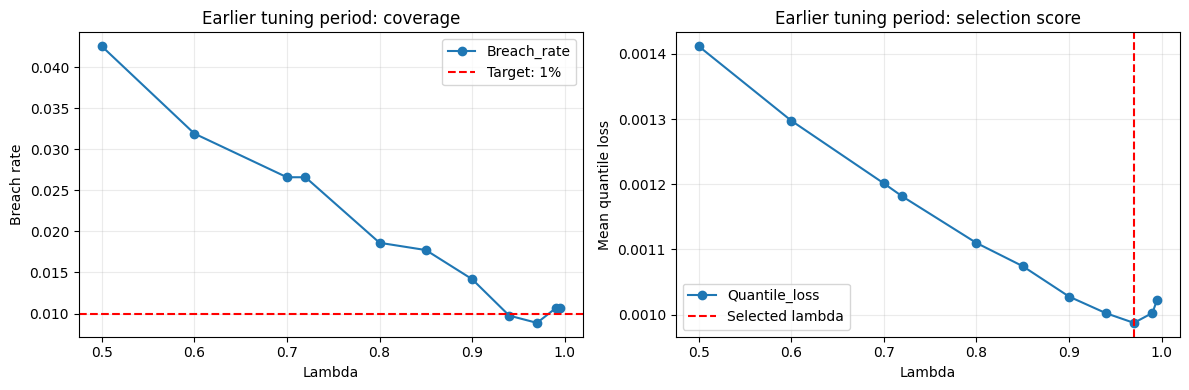

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sweep["Breach_rate"].plot(ax=axes[0], marker="o")
axes[0].axhline(ALPHA, color="red", linestyle="--", label="Target: 1%")
axes[0].set_ylabel("Breach rate")
axes[0].set_title("Earlier tuning period: coverage")
axes[0].legend()
sweep["Quantile_loss"].plot(ax=axes[1], marker="o")
axes[1].axvline(best_lambda, color="red", linestyle="--", label="Selected lambda")
axes[1].set_ylabel("Mean quantile loss")
axes[1].set_title("Earlier tuning period: selection score")
axes[1].legend()
for ax in axes:
    ax.set_xlabel("Lambda")
    ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()

## 6. Expanding Historical Simulation with daily returns
At each close, calculate the 1st percentile of all daily returns observed by that date. Forecasts begin after 252 valid daily returns. Old observations remain in the sample, and a new daily return is added as each trading day finishes.

That historical percentile is the forecast threshold for the next daily return. HistSim does not assume a Normal distribution. During testing, daily returns from earlier test days can join the history once they become known.

In [9]:
df["VaR_HistSim_1D"] = (
    df["Return"]
    .expanding(min_periods=HIST_MIN)
    .quantile(ALPHA)
)

## 7. GARCH(1,1): fit on daily returns and forecast one day ahead
Fit zero-mean GARCH with Normal innovations using the earlier daily returns:

$$r_{t+1}=\sigma_{t+1}z_{t+1},\qquad z_{t+1}\sim N(0,1),$$
$$\sigma^2_{t+1}=\omega+\alpha r_t^2+\beta\sigma_t^2.$$

The parameters stay fixed during testing. Each forecast still uses the returns observed up to that close to update the next-day variance.

The `h.1` output is the next daily return's forecast variance. Take its square root and divide by 100 to convert volatility from the percentage units used in fitting back to decimal units. Then multiply by the 1st-percentile Normal factor. This is the model's direct one-day conditional return quantile.

In [10]:
model_bt = arch_model(
    r_pct, mean="Zero", vol="GARCH", p=1, q=1, dist="normal"
)
result_bt = model_bt.fit(last_obs=n_train, disp="off")
if result_bt.convergence_flag != 0:
    raise RuntimeError("GARCH optimisation did not converge; inspect result_bt.optimization_result.")

# align='origin': the forecast on date t predicts the return ending on t+1
forecasts = result_bt.forecast(
    horizon=1, start=n_train - 1, align="origin", reindex=False
)
df["Vol_GARCH_1D"] = np.sqrt(forecasts.variance["h.1"]) / 100
df["VaR_GARCH_1D"] = norm.ppf(ALPHA) * df["Vol_GARCH_1D"]

print("GARCH fit ends:", last_training_date.date())
print("Fitted coefficients:")
print(result_bt.params)

GARCH fit ends: 2025-07-01
Fitted coefficients:
omega       0.860777
alpha[1]    0.100552
beta[1]     0.829702
Name: params, dtype: float64


## 8. Compare all four methods on the same test dates
Begin with the forecast made at the final training close. For each later forecast date, require both its next-day outcome and a threshold from every method. The check below confirms that all four methods cover the same dates as GARCH.

Compare each threshold on row t with `Return_1D_Forward` on that row. Do not compare it with `Return`, which is the return already observed by the time the forecast is made.

Each row in the results table uses the same daily outcomes. A rate near 1% is a coverage observation; quantile loss also scores where the threshold is placed. Neither number alone establishes that a method is best in every market regime.

In [11]:
var_columns = {
    "Rolling SD": "VaR_Rolling_1D",
    "EWMA": "VaR_EWMA_1D",
    "HistSim": "VaR_HistSim_1D",
    "GARCH": "VaR_GARCH_1D"
}

garch_dates = df.index[
    (df.index >= last_training_date)
    & df["Return_1D_Forward"].notna()
    & df["VaR_GARCH_1D"].notna()
]
common_mask = (
    df.index.isin(garch_dates)
    & df[list(var_columns.values())].notna().all(axis=1)
)
backtest = df.loc[common_mask].copy()
assert backtest.index.equals(garch_dates), "A method is missing forecasts on some GARCH dates."
if backtest.empty:
    raise ValueError("There are no common backtest dates.")

rows = []
for name, column in var_columns.items():
    breaches = backtest["Return_1D_Forward"] < backtest[column]
    backtest[f"Breach_{name.replace(' ', '_')}"] = breaches
    rows.append({
        "Model": name,
        "T": len(backtest),
        "Breaches": int(breaches.sum()),
        "Breach_rate": float(breaches.mean()),
        "Quantile_loss": quantile_loss(backtest["Return_1D_Forward"], backtest[column]),
        "Mean_VaR": float(backtest[column].mean())
    })

scores = pd.DataFrame(rows).set_index("Model")
print("Common forecast origins:", backtest.index[0].date(), "to", backtest.index[-1].date())
print("Identical comparisons per method:", len(backtest))
display(scores.sort_values("Quantile_loss").round(6))

Common forecast origins: 2025-07-01 to 2026-11-12
Identical comparisons per method: 346


,T,Breaches,Breach_rate,Quantile_loss,Mean_VaR
Model,,,,,
EWMA,346,5,0.014451,0.000726,-0.054073
Rolling SD,346,9,0.026012,0.000728,-0.051720
GARCH,346,1,0.002890,0.000746,-0.066079
HistSim,346,1,0.002890,0.000860,-0.080702


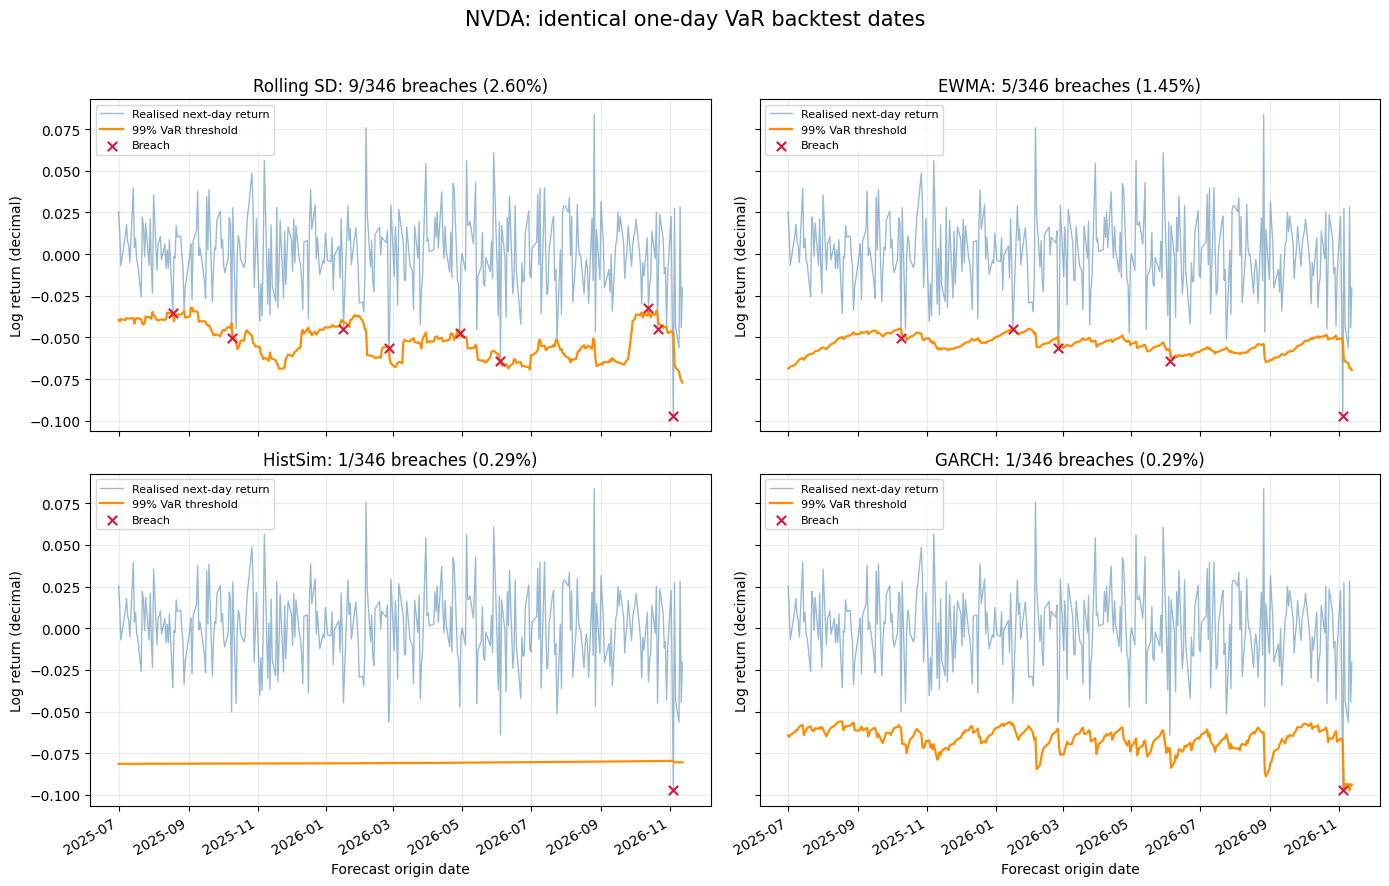

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9), sharex=True, sharey=True)
for ax, (name, column) in zip(axes.flat, var_columns.items()):
    breach = backtest[f"Breach_{name.replace(' ', '_')}"]
    ax.plot(backtest.index, backtest["Return_1D_Forward"], color="steelblue", alpha=0.55,
            linewidth=1, label="Realised next-day return")
    ax.plot(backtest.index, backtest[column], color="darkorange", linewidth=1.6,
            label="99% VaR threshold")
    ax.scatter(backtest.index[breach], backtest.loc[breach, "Return_1D_Forward"],
               color="crimson", marker="x", s=45, label="Breach", zorder=3)
    row = scores.loc[name]
    ax.set_title(f"{name}: {int(row['Breaches'])}/{int(row['T'])} breaches ({row['Breach_rate']:.2%})")
    ax.set_ylabel("Log return (decimal)")
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8, loc="upper left")
for ax in axes[-1]:
    ax.set_xlabel("Forecast origin date")
fig.suptitle(f"{TICKER}: identical one-day VaR backtest dates", fontsize=15)
fig.autofmt_xdate()
fig.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

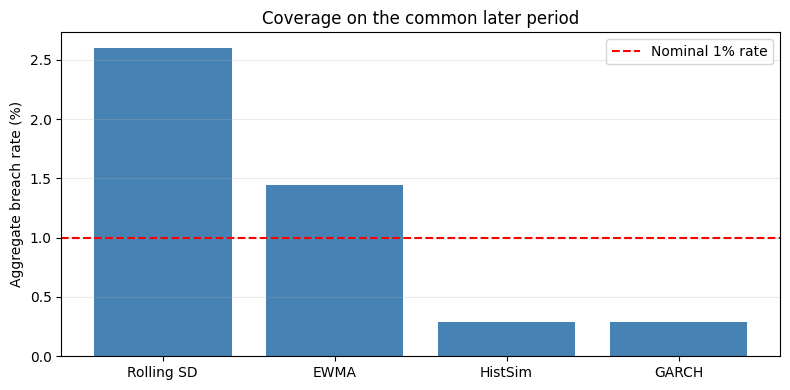

In [13]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(scores.index, 100 * scores["Breach_rate"], color="steelblue")
ax.axhline(100 * ALPHA, color="red", linestyle="--", label="Nominal 1% rate")
ax.set_ylabel("Aggregate breach rate (%)")
ax.set_title("Coverage on the common later period")
ax.legend()
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
plt.show()

## 9. Read the results
The following interpretation is generated when the notebook runs. The aggregate breach rate is the total breach count divided by the number of valid daily comparisons. It does not show when breaches occurred.

Consecutive outcomes now cover separate daily periods. However, breaches can still cluster when a model fails to respond well to changing market conditions. Non-overlapping daily outcomes do not guarantee independent breach flags.

In [14]:
lowest_loss = scores["Quantile_loss"].idxmin()
coverage_gap = (scores["Breach_rate"] - ALPHA).abs()
closest_coverage = ", ".join(
    scores.index[np.isclose(coverage_gap, coverage_gap.min(), rtol=0, atol=1e-12)]
)
selected = sweep.loc[best_lambda]

lines = [
    f"**Common sample:** {len(backtest)} forecast origins, from "
    f"{backtest.index[0].date()} to {backtest.index[-1].date()}.",
    f"**EWMA choice:** lambda = {best_lambda:g}, selected before the later backtest. "
    f"Its earlier tuning loss is {selected['Quantile_loss']:.6f} and its tuning breach rate is "
    f"{selected['Breach_rate']:.2%}.",
    "**Later-period results:**"
]
for name, row in scores.iterrows():
    lines.append(
        f"- **{name}:** {int(row['Breaches'])}/{int(row['T'])} breaches "
        f"({row['Breach_rate']:.2%}); mean quantile loss {row['Quantile_loss']:.6f}."
    )
lines += [
    f"**Lowest observed later-period quantile loss:** {lowest_loss}. "
    f"**Breach rate closest to 1%:** {closest_coverage}.",
    "These are descriptive comparisons on this sample, not proof of a universal winner. "
    "Do not retune lambda or the model specification on this later period and continue to call it untouched test data."
]
display(Markdown("\n\n".join(lines)))

**Common sample:** 346 forecast origins, from 2025-07-01 to 2026-11-12.

**EWMA choice:** lambda = 0.97, selected before the later backtest. Its earlier tuning loss is 0.000987 and its tuning breach rate is 0.89%.

**Later-period results:**

- **Rolling SD:** 9/346 breaches (2.60%); mean quantile loss 0.000728.

- **EWMA:** 5/346 breaches (1.45%); mean quantile loss 0.000726.

- **HistSim:** 1/346 breaches (0.29%); mean quantile loss 0.000860.

- **GARCH:** 1/346 breaches (0.29%); mean quantile loss 0.000746.

**Lowest observed later-period quantile loss:** EWMA. **Breach rate closest to 1%:** EWMA.

These are descriptive comparisons on this sample, not proof of a universal winner. Do not retune lambda or the model specification on this later period and continue to call it untouched test data.

## 10. What this first study can and cannot establish
- **Same task:** every method forecasts the next daily return's lower 1% threshold and is scored on identical later dates.
- **Earlier data first:** GARCH is fitted and EWMA's lambda is chosen using only information available by the training cutoff. There is no need to discard observed prices or insert a blank day between training and testing.
- **Daily updates:** during testing, new observed returns may update forecasts. The selected lambda and GARCH parameters stay fixed.
- **Different mechanisms:** rolling SD uses the latest 21 returns; EWMA fades past squared returns; HistSim retains all observed daily returns; GARCH combines shock response, persistence and mean reversion.
- **Distribution choices:** rolling SD, EWMA and GARCH use Normal return assumptions. HistSim estimates the daily quantile directly from its historical sample. All four are one-day methods here.
- **Dependence can remain:** daily outcome periods do not overlap, but breach flags may still be dependent. The code does not assume that non-overlap proves independence.
- **Limited tail evidence:** a few hundred test dates give only a few expected breaches at a 1% rate. Small score differences may not be reliable.
- **Study scope:** this is a first comparison of the current methods. Additional model variants and diagnostics can follow after this workflow is understood.

Each run downloads data directly. Updated or revised prices can change the 80/20 cutoff and results, so note the printed date range when comparing runs. No results are prefilled in this file.